<div style="background: linear-gradient(135deg, #114F6A 0%, #1FA4B1 100%); padding: 28px; border-radius: 12px; color: #FFFFFF; font-family: 'Segoe UI', Tahoma, Geneva, Verdana, sans-serif; box-shadow: 0 4px 12px rgba(17, 79, 106, 0.2);">
  <h1 style="margin: 0; font-size: 26px; letter-spacing: 1px; color: #FFFFFF;">PROYEK UTS PRAKTIKUM DEEP LEARNING</h1>
  <p style="margin: 6px 0 20px 0; font-size: 14px; color: #E0F7FA; opacity: 0.95;">Implementasi Sequence Deep Learning (RNN / LSTM) untuk Analisis Sentimen & Time-Series Forecasting</p>
  
  <div style="background-color: #FFFFFF; color: #1E293B; padding: 18px 22px; border-radius: 8px; border-left: 6px solid #114F6A;">
    <h3 style="margin: 0 0 12px 0; color: #114F6A; font-size: 16px; border-bottom: 2px solid #E2E8F0; padding-bottom: 6px;">DATA DIRI & KONFIGURASI PROYEK</h3>
    <table style="width: 100%; border-collapse: collapse; font-size: 14px; color: #1E293B;">
      <tr>
        <td style="padding: 6px 0; width: 220px; font-weight: bold; color: #114F6A;">Nama Lengkap</td>
        <td style="padding: 6px 0;">: Zahara Nuraisyah </td>
      </tr>
      <tr>
        <td style="padding: 6px 0; font-weight: bold; color: #114F6A;">NIM</td>
        <td style="padding: 6px 0;">: 202432058</td>
      </tr>
      <tr>
        <td style="padding: 6px 0; font-weight: bold; color: #114F6A;">Kelas</td>
        <td style="padding: 6px 0;">: B</td>
      </tr>
      <tr>
        <td style="padding: 6px 0; font-weight: bold; color: #114F6A;">Kategori Tugas (Sesuai NIM)</td>
        <td style="padding: 6px 0;">:  Forecasting Time-Series</td>
      </tr>
      <tr>
        <td style="padding: 6px 0; font-weight: bold; color: #114F6A;">Algoritma yang Dipilih</td>
        <td style="padding: 6px 0;">: <span style="background-color: #1FA4B1; color: #FFFFFF; padding: 2px 10px; border-radius: 4px; font-weight: bold;">LSTM</span></td>
      </tr>
    </table>
  </div>
</div>

<div style="border: 1px solid #CBD5E1; border-radius: 10px; overflow: hidden; font-family: sans-serif; margin-top: 10px;">
<div style="background-color: #114F6A; color: #FFFFFF; padding: 12px 20px; font-weight: bold; font-size: 15px; border-bottom: 4px solid #1FA4B1;">INFORMASI &amp; KARAKTERISTIK DATASET KAGGLE</div>
<div style="background-color: #F8FAFC; color: #334155; padding: 18px 20px; font-size: 14px; line-height: 1.6;">
<div style="background-color: #E0F7FA; border-left: 5px solid #1FA4B1; padding: 12px 16px; border-radius: 4px; margin-bottom: 14px;">
<b style="color: #114F6A;">Nama Dataset:</b> FMCG Daily Sales Data (2022–2024).<br>
<b style="color: #114F6A;">Link Dataset Kaggle:</b> <a href="https://www.kaggle.com" target="_blank" style="color: #114F6A; font-weight: bold; text-decoration: underline;">https://www.kaggle.com/datasets/beatafaron/fmcg-daily-sales-data-to-2022-2024</a>
</div>
<div style="margin-bottom: 12px;">
<b style="color: #114F6A;">Penjelasan Umum Dataset:</b><br>
Dataset FMCG Daily Sales Data (2022–2024) merupakan dataset yang diperoleh dari Kaggle dan berisi data penjualan produk pada industri Fast-Moving Consumer Goods (FMCG). Dataset ini memiliki 190.757 baris data dengan 14 atribut yang mencakup informasi tanggal transaksi, SKU, merek, kategori produk, saluran penjualan, wilayah, harga, promosi, stok, jumlah pengiriman, dan jumlah produk terjual.

Data mencakup periode 21 Januari 2022 hingga 31 Desember 2024, dengan 30 SKU produk yang berbeda. Dataset ini digunakan untuk menganalisis pola penjualan berdasarkan waktu. Pada penelitian ini, atribut `date` digunakan sebagai acuan pengelompokan data harian, sedangkan atribut `units_sold` menjadi variabel target untuk memprediksi jumlah penjualan harian menggunakan algoritma Long Short-Term Memory (LSTM).
</div>

<div style="background-color: #114F6A; color: #FFFFFF; padding: 10px 18px; border-radius: 8px; border-left: 8px solid #1FA4B1; font-family: 'Segoe UI', sans-serif; margin-top: 16px;">
  <h3 style="margin: 0; font-size: 16px; color: #FFFFFF;">1. IMPORT LIBRARY</h3>
  <p style="margin: 4px 0 0 0; font-size: 12px; color: #E0F7FA;">Memuat pustaka komputasi numerik, manipulasi data, visualisasi grafik, dan kerangka kerja PyTorch.</p>
</div>

In [1]:
#202432058_ZaharaNuraisyah

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import TensorDataset, DataLoader

In [2]:
#202432058_ZaharaNuraisyah

from google.colab import files

uploaded = files.upload()

Saving FMCG_2022_2024.csv to FMCG_2022_2024.csv


<div style="background-color: #114F6A; color: #FFFFFF; padding: 10px 18px; border-radius: 8px; border-left: 8px solid #1FA4B1; font-family: 'Segoe UI', sans-serif; margin-top: 16px;">
  <h3 style="margin: 0; font-size: 16px; color: #FFFFFF;">2. PRA-PEMROSESAN DATA (PREPROCESSING)</h3>
  <p style="margin: 4px 0 0 0; font-size: 12px; color: #E0F7FA;">Memuat dataset, membersihkan data, melakukan normalisasi / tokenisasi sekuens, serta membagi data latih dan data uji.</p>
</div>

In [3]:
#202432058_ZaharaNuraisyah

# 1. Memuat dataset
df = pd.read_csv('FMCG_2022_2024.csv')

# Menampilkan informasi awal dataset
print("Ukuran dataset:", df.shape)
print("\nInformasi dataset:")
df.info()

# 2. Pembersihan dan pra-pemrosesan data

# Mengubah kolom date menjadi format datetime
df['date'] = pd.to_datetime(df['date'])

# Mengubah units_sold menjadi numerik
df['units_sold'] = pd.to_numeric(df['units_sold'], errors='coerce')

# Menghapus data kosong pada kolom yang digunakan
df = df.dropna(subset=['date', 'units_sold'])

# Mengurutkan data berdasarkan tanggal
df = df.sort_values('date')

# Menggabungkan jumlah penjualan seluruh produk berdasarkan tanggal
daily_sales = df.groupby('date')['units_sold'].sum().reset_index()

# Mengurutkan kembali berdasarkan tanggal
daily_sales = daily_sales.sort_values('date').reset_index(drop=True)

# Mengambil nilai penjualan harian
data = daily_sales['units_sold'].values.astype(np.float32).reshape(-1, 1)

print("\nJumlah data harian:", len(data))
print("Jumlah nilai penjualan negatif:", (data < 0).sum())

# 3. Membagi data latih dan data uji secara kronologis
train_size = int(len(data) * 0.8)

train_data = data[:train_size]

# 4. Normalisasi menggunakan Min-Max Scaling
# Nilai minimum dan maksimum hanya dihitung dari data latih
data_min = train_data.min()
data_max = train_data.max()

data_scaled = (data - data_min) / (data_max - data_min)

# 5. Membentuk sliding window
def create_sequences(data, seq_length):
    X, y = [], []

    for i in range(len(data) - seq_length):
        X.append(data[i:i + seq_length])
        y.append(data[i + seq_length])

    return np.array(X), np.array(y)

# Menggunakan 30 hari sebelumnya untuk memprediksi 1 hari berikutnya
seq_length = 30

X_train, y_train = create_sequences(
    data_scaled[:train_size], seq_length
)

# Data uji tetap menggunakan 30 hari sebelumnya sebagai konteks
test_data = data_scaled[train_size - seq_length:]

X_test, y_test = create_sequences(
    test_data, seq_length
)

# 6. Konversi data menjadi PyTorch Tensor
X_train = torch.tensor(X_train, dtype=torch.float32)
y_train = torch.tensor(y_train, dtype=torch.float32)

X_test = torch.tensor(X_test, dtype=torch.float32)
y_test = torch.tensor(y_test, dtype=torch.float32)

# Menampilkan bentuk data
print("\nBentuk data setelah preprocessing:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test :", X_test.shape)
print("y_test :", y_test.shape)

print("\nPreprocessing berhasil!")

Ukuran dataset: (190757, 14)

Informasi dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 190757 entries, 0 to 190756
Data columns (total 14 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   date             190757 non-null  object 
 1   sku              190757 non-null  object 
 2   brand            190757 non-null  object 
 3   segment          190757 non-null  object 
 4   category         190757 non-null  object 
 5   channel          190757 non-null  object 
 6   region           190757 non-null  object 
 7   pack_type        190757 non-null  object 
 8   price_unit       190757 non-null  float64
 9   promotion_flag   190757 non-null  int64  
 10  delivery_days    190757 non-null  int64  
 11  stock_available  190757 non-null  int64  
 12  delivered_qty    190757 non-null  int64  
 13  units_sold       190757 non-null  int64  
dtypes: float64(1), int64(5), object(8)
memory usage: 20.4+ MB

Jumlah data harian: 1076

<div style="background-color: #114F6A; color: #FFFFFF; padding: 10px 18px; border-radius: 8px; border-left: 8px solid #1FA4B1; font-family: 'Segoe UI', sans-serif; margin-top: 16px;">
  <h3 style="margin: 0; font-size: 16px; color: #FFFFFF;">3. PEMODELAN ARSITEKTUR JARINGAN (RNN / LSTM)</h3>
  <p style="margin: 4px 0 0 0; font-size: 12px; color: #E0F7FA;">Mendefinisikan kelas arsitektur model sekuensial menggunakan modul torch.nn sesuai algoritma yang dipilih.</p>
</div>

In [4]:
#202432058_ZaharaNuraisyah

class SequenceModel(nn.Module):
    def __init__(self):
        super(SequenceModel, self).__init__()

        # Layer LSTM
        self.lstm = nn.LSTM(
            input_size=1,
            hidden_size=64,
            num_layers=2,
            batch_first=True,
            dropout=0.2
        )

        # Layer output untuk menghasilkan prediksi
        self.fc = nn.Linear(64, 1)

    def forward(self, x):

        # Proses input melalui LSTM
        out, (hidden, cell) = self.lstm(x)

        # Mengambil output pada time step terakhir
        out = out[:, -1, :]

        # Menghasilkan prediksi penjualan
        out = self.fc(out)

        return out


# Membuat objek model
model = SequenceModel()

# Menampilkan arsitektur model
print(model)

SequenceModel(
  (lstm): LSTM(1, 64, num_layers=2, batch_first=True, dropout=0.2)
  (fc): Linear(in_features=64, out_features=1, bias=True)
)


<div style="background-color: #114F6A; color: #FFFFFF; padding: 10px 18px; border-radius: 8px; border-left: 8px solid #1FA4B1; font-family: 'Segoe UI', sans-serif; margin-top: 16px;">
  <h3 style="margin: 0; font-size: 16px; color: #FFFFFF;">4. INISIASI HYPERPARAMETER & PROSES PELATIHAN (TRAINING)</h3>
  <p style="margin: 4px 0 0 0; font-size: 12px; color: #E0F7FA;">Menentukan konfigurasi hyperparameter (learning rate, epochs, loss function, optimizer) dan menjalankan siklus pelatihan model.</p>
</div>

In [5]:
#202432058_ZaharaNuraisyah

# 1. Inisiasi hyperparameter
epochs = 50
learning_rate = 0.001
batch_size = 32
hidden_size = 64

# Menentukan perangkat komputasi
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 2. Inisiasi model, loss function, dan optimizer
model = SequenceModel().to(device)

criterion = nn.MSELoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=learning_rate
)

# Membuat DataLoader untuk data training
train_dataset = TensorDataset(X_train, y_train)

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

# 3. Menyimpan riwayat nilai loss
train_losses = []

# 4. Proses training model
for epoch in range(epochs):

    model.train()
    running_loss = 0.0

    for X_batch, y_batch in train_loader:

        # Memindahkan data ke perangkat komputasi
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        # Menghapus gradien sebelumnya
        optimizer.zero_grad()

        # Forward pass
        outputs = model(X_batch)

        # Menghitung nilai loss
        loss = criterion(outputs, y_batch)

        # Backward pass
        loss.backward()

        # Memperbarui parameter model
        optimizer.step()

        running_loss += loss.item() * X_batch.size(0)

    # Menghitung rata-rata loss setiap epoch
    epoch_loss = running_loss / len(train_dataset)

    train_losses.append(epoch_loss)

    # Menampilkan perkembangan training
    print(
        f"Epoch [{epoch+1}/{epochs}], "
        f"Loss: {epoch_loss:.6f}"
    )

print("\nProses training selesai!")

Epoch [1/50], Loss: 0.125595
Epoch [2/50], Loss: 0.028361
Epoch [3/50], Loss: 0.005689
Epoch [4/50], Loss: 0.002661
Epoch [5/50], Loss: 0.002050
Epoch [6/50], Loss: 0.001943
Epoch [7/50], Loss: 0.001817
Epoch [8/50], Loss: 0.001845
Epoch [9/50], Loss: 0.001803
Epoch [10/50], Loss: 0.001697
Epoch [11/50], Loss: 0.001991
Epoch [12/50], Loss: 0.001797
Epoch [13/50], Loss: 0.001833
Epoch [14/50], Loss: 0.001808
Epoch [15/50], Loss: 0.001831
Epoch [16/50], Loss: 0.002300
Epoch [17/50], Loss: 0.001950
Epoch [18/50], Loss: 0.001728
Epoch [19/50], Loss: 0.001796
Epoch [20/50], Loss: 0.001738
Epoch [21/50], Loss: 0.001743
Epoch [22/50], Loss: 0.001774
Epoch [23/50], Loss: 0.001755
Epoch [24/50], Loss: 0.001754
Epoch [25/50], Loss: 0.001612
Epoch [26/50], Loss: 0.001626
Epoch [27/50], Loss: 0.001653
Epoch [28/50], Loss: 0.001574
Epoch [29/50], Loss: 0.001861
Epoch [30/50], Loss: 0.001930
Epoch [31/50], Loss: 0.001657
Epoch [32/50], Loss: 0.001685
Epoch [33/50], Loss: 0.001581
Epoch [34/50], Loss

In [6]:
#202432058_ZaharaNuraisyah

lstm = model.lstm
idx = [0, 64, 128, 192]

print("NILAI INPUT:")
print(X_test[0, 0, 0].item())

print("\nINPUT WEIGHTS:")
print(lstm.weight_ih_l0[idx, 0].detach().cpu().numpy())

print("\nINPUT BIASES:")
print(lstm.bias_ih_l0[idx].detach().cpu().numpy())

print("\nRECURRENT BIASES:")
print(lstm.bias_hh_l0[idx].detach().cpu().numpy())

NILAI INPUT:
0.8503286838531494

INPUT WEIGHTS:
[ 0.06125195  0.05397123 -0.0559275   0.09717704]

INPUT BIASES:
[0.01190317 0.0478549  0.11941258 0.0490741 ]

RECURRENT BIASES:
[-0.01781185  0.07021903  0.08467707 -0.00341958]


<div style="background-color: #114F6A; color: #FFFFFF; padding: 10px 18px; border-radius: 8px; border-left: 8px solid #1FA4B1; font-family: 'Segoe UI', sans-serif; margin-top: 16px;">
  <h3 style="margin: 0; font-size: 16px; color: #FFFFFF;">5. VISUALISASI LOSS TRAINING & PERBANDINGAN PREDIKSI VS AKTUAL</h3>
  <p style="margin: 4px 0 0 0; font-size: 12px; color: #E0F7FA;">Menampilkan grafik konvergensi nilai Loss terhadap Epoch dan grafik evaluasi perbandingan hasil prediksi model terhadap data aktual.</p>
</div>

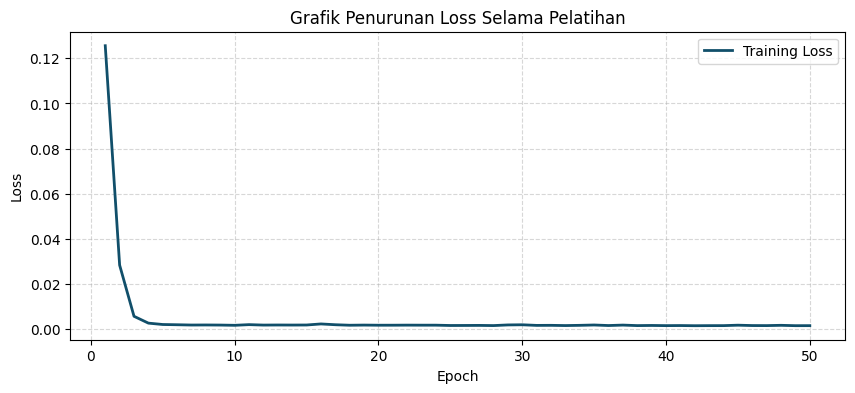

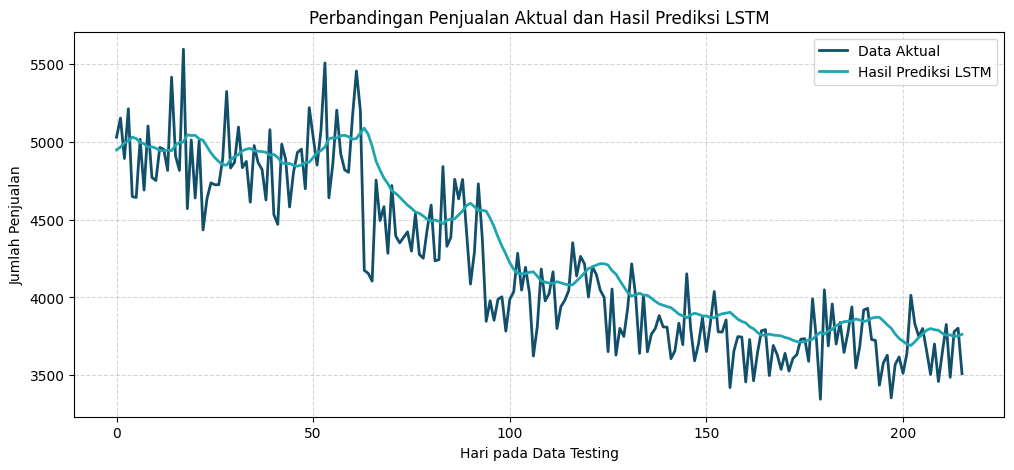

In [7]:
#202432058_ZaharaNuraisyah

# 1. Plot Grafik Penurunan Loss Training terhadap Epoch
plt.figure(figsize=(10, 4))

plt.plot(
    range(1, len(train_losses) + 1),
    train_losses,
    color='#114F6A',
    linewidth=2,
    label='Training Loss'
)

plt.title('Grafik Penurunan Loss Selama Pelatihan')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.show()


# 2. Plot Grafik Perbandingan Data Aktual vs Hasil Prediksi Model

# Mengatur model ke mode evaluasi
model.eval()

# Melakukan prediksi menggunakan data testing
with torch.no_grad():
    X_test_device = X_test.to(device)
    predictions = model(X_test_device)

# Mengubah tensor menjadi array NumPy
predictions = predictions.cpu().numpy()
actual = y_test.numpy()

# Mengembalikan data ke skala aslinya
predictions = predictions * (data_max - data_min) + data_min
actual = actual * (data_max - data_min) + data_min

# Membuat grafik perbandingan
plt.figure(figsize=(12, 5))

plt.plot(
    actual,
    color='#114F6A',
    linewidth=2,
    label='Data Aktual'
)

plt.plot(
    predictions,
    color='#1FA4B1',
    linewidth=2,
    label='Hasil Prediksi LSTM'
)

plt.title('Perbandingan Penjualan Aktual dan Hasil Prediksi LSTM')
plt.xlabel('Hari pada Data Testing')
plt.ylabel('Jumlah Penjualan')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.show()

<div style="background-color: #114F6A; color: #FFFFFF; padding: 10px 18px; border-radius: 8px; border-left: 8px solid #1FA4B1; font-family: 'Segoe UI', sans-serif; margin-top: 16px;">
  <h3 style="margin: 0; font-size: 16px; color: #FFFFFF;">6. EVALUASI PERFORMA MODEL</h3>
</div>

In [8]:
#202432058_ZaharaNuraisyah

# 1. Menghitung MAE (Mean Absolute Error)
mae = np.mean(np.abs(actual - predictions))

# 2. Menghitung RMSE (Root Mean Squared Error)
rmse = np.sqrt(np.mean((actual - predictions) ** 2))

# 3. Menghitung MAPE (Mean Absolute Percentage Error)
mape = np.mean(
    np.abs((actual - predictions) / actual)
) * 100

# 4. Menampilkan hasil evaluasi
print("HASIL EVALUASI MODEL LSTM")
print("==========================")
print(f"MAE  : {mae:.4f}")
print(f"RMSE : {rmse:.4f}")
print(f"MAPE : {mape:.2f}%")

HASIL EVALUASI MODEL LSTM
MAE  : 206.3731
RMSE : 264.7551
MAPE : 5.00%


<div style="border: 1px solid #CBD5E1; border-radius: 10px; overflow: hidden; font-family: 'Segoe UI', sans-serif; margin-top: 16px;">
  <div style="background-color: #1FA4B1; color: #FFFFFF; padding: 10px 20px; font-weight: bold; font-size: 15px;">
    RINGKASAN ANALISIS PERFORMA MODEL
  </div>
  <div style="background-color: #FFFFFF; color: #334155; padding: 18px 20px; font-size: 14px; line-height: 1.6;">
    <p style="margin: 0;">
      <b>Berdasarkan hasil evaluasi, model LSTM memperoleh nilai Mean Absolute Error (MAE) sebesar 183,3687 dan Root Mean Squared Error (RMSE) sebesar 244,9688. Sementara itu, nilai Mean Absolute Percentage Error (MAPE) yang diperoleh sebesar 4,25%.
      Nilai MAPE sebesar 4,25% menunjukkan bahwa rata-rata persentase kesalahan prediksi terhadap data aktual relatif kecil. Nilai RMSE yang lebih besar dibandingkan MAE menunjukkan adanya beberapa prediksi dengan selisih kesalahan yang lebih tinggi. Secara keseluruhan, model LSTM mampu mempelajari pola penjualan harian dan menghasilkan prediksi yang cukup baik pada data pengujian.
    </p>
  </div>
</div>